# Red-noise parameters vs the cluster light fraction

Do the red-noise (RN) parameters measured from the light curves depend on how much of the
aperture light is the cluster? Two independent cluster-fraction measurements are compared:

| Symbol | Source | Meaning |
|---|---|---|
| **f_TESS** | `crowding_analysis.ipynb` | literature cluster light / (ELK flux − zodiacal light) |
| **f_Gaia** | `gaia_cluster_share.ipynb` | cluster share of the resolved Gaia light (can be < 0) |

The RN parameters are the per-cluster medians over sector combinations, as used in
`Correlation_Analysis/`:

| Parameter | What it is | Source |
|---|---|---|
| `gp_rn_log10_S0` | log RN power spectral density at 1 day⁻¹ (normalised flux) | GP power law |
| `gp_rn_rms_band` | RN rms integrated over the fitted band (log₁₀) | GP power law |
| `gp_rn_alpha_band` | in-band log–log slope of the RN spectrum | GP power law |
| `gp_rn_wn_ratio` | RN / white-noise PSD at 1 day⁻¹ (log₁₀) | GP |
| `rn_log10_N` | RN normalisation of the Lomb–Scargle continuum | LSP fit |
| `rn_alpha` | RN slope of the Lomb–Scargle continuum | LSP fit |
| `gp_jitter` | excess white noise (log₁₀) | GP |

**What pure dilution predicts.** Each light curve is normalised by its median flux, which is the
cluster plus the field. If the field is quiet, the cluster's fractional variability is scaled by
f_cl, so:
- **Amplitudes scale with f_cl:** rms ∝ f_cl (slope +1 in log–log) and PSD normalisations
  (S0, N) ∝ f_cl² (slope +2).
- **Slopes (α) don't depend on f_cl.** Dilution multiplies the whole spectrum by a constant.
- **RN / white-noise ratio:** the white noise is photon noise of the *total* flux, so it doesn't
  scale with f_cl, and the ratio should rise with f_cl (∝ f_cl²).

Variable field stars break this. They add their own red noise, which flattens these relations
and can change α. Measured slopes shallower than +2 / +1 therefore mean either noisy f_cl
(regression dilution) or field variability.

In [1]:
%load_ext autoreload
%autoreload 2
import os, sys, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
warnings.filterwarnings('ignore', category=RuntimeWarning)

HERE = os.path.abspath('.')
sys.path.insert(0, HERE)
from crowd import catalogs as C
sys.path.insert(0, os.path.join(C.LC_DIR, '..', 'Correlation_Analysis'))
import analysis_utils as A

FIG = os.path.join(HERE, 'figs'); os.makedirs(FIG, exist_ok=True)
GAL = ['MW', 'LMC', 'SMC']
SUBSETS = GAL + ['all']
COL = {'MW': '#2a78d6', 'LMC': '#eb6834', 'SMC': '#1baf7a'}
MRK = {'MW': 'o', 'LMC': 's', 'SMC': '^'}
INK, MUTED = '#2c2c2a', '#8f8e88'
pd.set_option('display.width', 220); pd.set_option('display.max_columns', 40)
plt.rcParams.update({'figure.facecolor': '#fcfcfb', 'axes.facecolor': '#fcfcfb',
                     'axes.grid': True, 'grid.color': '#e6e5e0', 'axes.axisbelow': True,
                     'axes.spines.top': False, 'axes.spines.right': False, 'legend.frameon': False,
                     'axes.edgecolor': MUTED, 'axes.labelcolor': INK, 'xtick.color': INK,
                     'ytick.color': INK, 'lines.linewidth': 2})
def save(fig, name):
    fig.savefig(os.path.join(FIG, name), dpi=150, bbox_inches='tight')

RN = ['gp_rn_log10_S0', 'gp_rn_rms_band', 'gp_rn_alpha_band', 'gp_rn_wn_ratio',
      'rn_log10_N', 'rn_alpha', 'gp_jitter']
PRED_SLOPE = {'gp_rn_log10_S0': 2, 'gp_rn_rms_band': 1, 'gp_rn_alpha_band': 0,
              'gp_rn_wn_ratio': 2, 'rn_log10_N': 2, 'rn_alpha': 0, 'gp_jitter': None}
FMEAS = {'f_TESS': 'log₁₀ f_TESS', 'f_Gaia': 'f_Gaia'}

## 1 · Data

The cluster table (median over sector combinations, same transforms as `Correlation_Analysis/`)
is merged with both cluster-fraction measurements. `log_f_TESS` is used wherever a
log-log slope is fitted. Spearman correlations don't depend on the transform.

In [2]:
GT = os.path.join(C.LC_DIR, '..', 'GenerateTable_CGW', 'data')
rows = A.load_rows(os.path.join(GT, 'cluster_table_Sep23_all_combos_le3sectors.pkl'), verbose=False)
ct = A.cluster_table(rows)
keep = ['name', 'age'] + RN + [c for c in ct.columns if c.startswith('frac_gp_rn_near')]
ct = ct[keep]
bud = pd.read_csv(os.path.join(HERE, 'crowding_budget.csv'))[['name', 'origin', 'f_cl_astro']]
gsh = pd.read_csv(os.path.join(HERE, 'gaia_cluster_share.csv'))[['name', 'f_gaia', 'sig_total']]
df = ct.merge(bud, on='name', how='inner').merge(gsh, on='name', how='left')
df = df.rename(columns={'f_cl_astro': 'f_TESS', 'f_gaia': 'f_Gaia'})
df['log_f_TESS'] = np.log10(df.f_TESS.where(df.f_TESS > 0))
print(f'{len(df)} clusters; with f_TESS: {df.f_TESS.notna().sum()}, with f_Gaia: {df.f_Gaia.notna().sum()}')
display(df.groupby('origin')[RN].count().loc[GAL])

348 clusters; with f_TESS: 325, with f_Gaia: 348


,gp_rn_log10_S0,gp_rn_rms_band,gp_rn_alpha_band,gp_rn_wn_ratio,rn_log10_N,rn_alpha,gp_jitter
origin,,,,,,,
MW,124,124,124,124,124,124,124
LMC,118,118,118,118,118,118,118
SMC,106,106,106,106,106,106,106


## 2 · Correlation map

Spearman ρ between each RN parameter and each cluster-fraction measure, per galaxy and pooled,
with bootstrap 95% CIs (resampling clusters). P-values are Benjamini–Hochberg corrected within
each cluster-fraction measure (7 parameters × 4 subsets = 28 tests). Cells marked • have q < 0.05.

The pooled ("all") column mixes galaxies with very different f_cl and noise properties. Use it
with care; the per-galaxy columns are the real test.

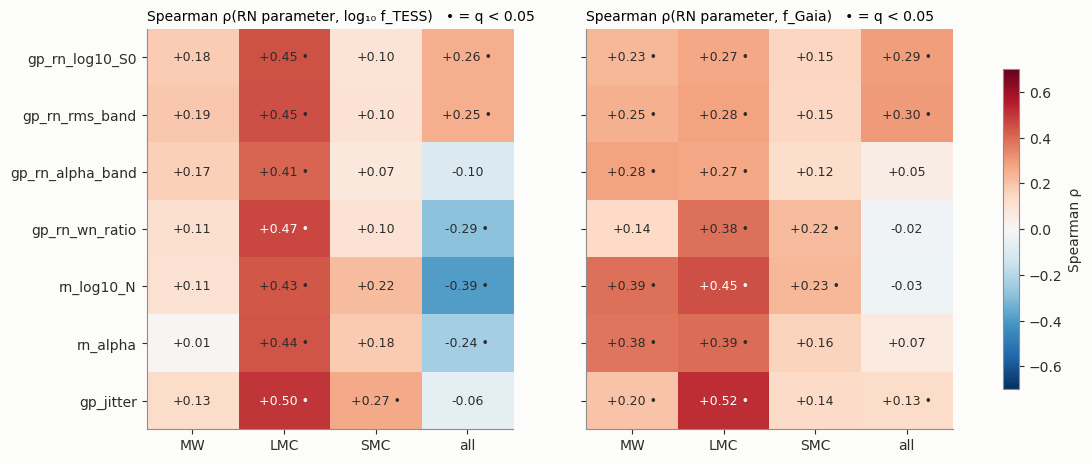

q           rho       
fmeas                   f_Gaia f_TESS f_Gaia f_TESS
param            subset                            
gp_jitter        LMC     0.000  0.000  0.518  0.501
                 MW      0.039  0.210  0.201  0.130
                 SMC     0.202  0.032  0.136  0.267
                 all     0.029  0.316  0.128 -0.063
gp_rn_alpha_band LMC     0.007  0.000  0.271  0.406
                 MW      0.005  0.103  0.281  0.167
                 SMC     0.241  0.519  0.121  0.075
                 all     0.371  0.103  0.051 -0.102
gp_rn_log10_S0   LMC     0.007  0.000  0.273  0.447
                 MW      0.019  0.081  0.231  0.179
                 SMC     0.164  0.409  0.153  0.098
                 all     0.000  0.000  0.292  0.256
gp_rn_rms_band   LMC     0.006  0.000  0.282  0.449
                 MW      0.012  0.069  0.246  0.190
                 SMC     0.169  0.409  0.147  0.099
                 all     0.000  0.000  0.297  0.253
gp_rn_wn_ratio   LMC     0.000  0.000  0.383  0.469
                 MW      0.165  0.297  0.139  0.109
                 SMC     0.037  0.409  0.221  0.103
                 all     0.648  0.000 -0.025 -0.287
rn_alpha         LMC     0.000  0.000  0.392  0.440
                 MW      0.000  0.930  0.376  0.008
                 SMC     0.160  0.143  0.157  0.183
                 all     0.240  0.000  0.068 -0.237
rn_log10_N       LMC     0.000  0.000  0.450  0.432
                 MW      0.000  0.297  0.387  0.108
                 SMC     0.029  0.081  0.234  0.221
                 all     0.608  0.000 -0.029 -0.391

In [3]:
res = []
for fm in FMEAS:
    for p in RN:
        for s in SUBSETS:
            d = df if s == 'all' else df[df.origin == s]
            d = d[[p, fm]].dropna()
            if len(d) < 15:
                continue
            r, pv, (lo, hi) = A.spearman_ci(d[fm], d[p], n_boot=1000, seed=0)
            res.append(dict(fmeas=fm, param=p, subset=s, n=len(d), rho=r, lo=lo, hi=hi, p=pv))
res = pd.DataFrame(res)
res['q'] = res.groupby('fmeas').p.transform(lambda x: A.bh_fdr(x.values))

fig, axs = plt.subplots(1, 2, figsize=(13, 5.2), sharey=True)
for ax, fm in zip(axs, FMEAS):
    m = res[res.fmeas == fm].pivot(index='param', columns='subset', values='rho').reindex(index=RN, columns=SUBSETS)
    q = res[res.fmeas == fm].pivot(index='param', columns='subset', values='q').reindex(index=RN, columns=SUBSETS)
    im = ax.imshow(m.values, cmap='RdBu_r', vmin=-0.7, vmax=0.7, aspect='auto')
    for i in range(m.shape[0]):
        for j in range(m.shape[1]):
            v = m.values[i, j]
            if np.isfinite(v):
                mark = ' •' if q.values[i, j] < 0.05 else ''
                ax.text(j, i, f'{v:+.2f}{mark}', ha='center', va='center', fontsize=9,
                        color='white' if abs(v) > 0.45 else INK)
    ax.set_xticks(range(len(SUBSETS))); ax.set_xticklabels(SUBSETS)
    ax.set_yticks(range(len(RN))); ax.set_yticklabels(RN)
    ax.grid(False)
    ax.set_title(f'Spearman ρ(RN parameter, {FMEAS[fm]})   • = q < 0.05', loc='left', fontsize=10)
fig.colorbar(im, ax=axs, shrink=.8, label='Spearman ρ')
save(fig, 'fig_rn_fcl_heatmap.png'); plt.show()
display(res.pivot_table(index=['param', 'subset'], columns='fmeas', values=['rho', 'q']).round(3))

## 3 · The key relations, with the dilution prediction

The top row is against log f_TESS. Grey lines show the slope pure dilution predicts (+2 for PSD
normalisations, +1 for rms, 0 for slopes), drawn through each galaxy's median point. The bottom
row is against f_Gaia, which is linear and can be negative.

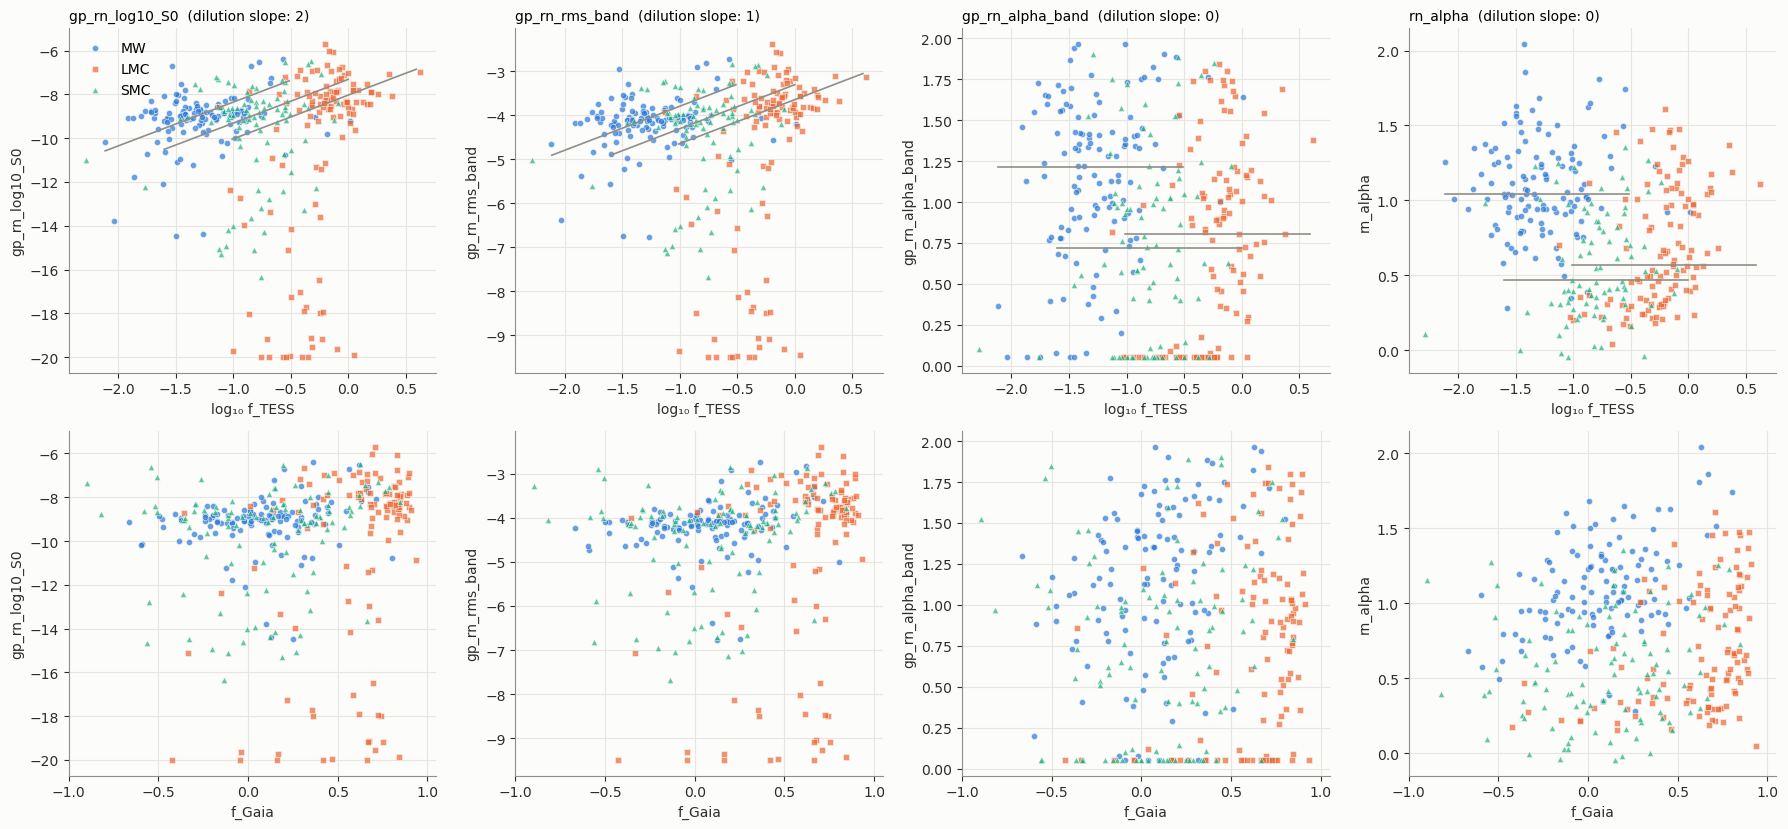

In [4]:
SHOW = ['gp_rn_log10_S0', 'gp_rn_rms_band', 'gp_rn_alpha_band', 'rn_alpha']
fig, axs = plt.subplots(2, 4, figsize=(18, 8.4))
for k, p in enumerate(SHOW):
    for o in GAL:
        d = df[df.origin == o]
        kw = dict(s=20, marker=MRK[o], color=COL[o], alpha=.7, edgecolor='#fcfcfb', lw=.5, label=o)
        axs[0, k].scatter(d.log_f_TESS, d[p], **kw)
        axs[1, k].scatter(d.f_Gaia, d[p], **kw)
        sl = PRED_SLOPE[p]
        x0, y0 = d.log_f_TESS.median(), d[p].median()
        if sl is not None and np.isfinite(x0) and np.isfinite(y0):
            xx = np.array([x0 - 0.8, x0 + 0.8])
            axs[0, k].plot(xx, y0 + sl * (xx - x0), color=MUTED, lw=1.2)
    axs[0, k].set(xlabel='log₁₀ f_TESS', ylabel=p)
    axs[1, k].set(xlabel='f_Gaia', ylabel=p, xlim=(-1, 1.05))
    axs[0, k].set_title(f'{p}  (dilution slope: {PRED_SLOPE[p]})', loc='left', fontsize=10)
axs[0, 0].legend(loc='upper left')
fig.tight_layout(); save(fig, 'fig_rn_vs_fcl_scatter.png'); plt.show()

## 4 · Slope test against the dilution prediction

An OLS slope of each amplitude parameter on log f_TESS, per galaxy, with a bootstrap CI.
Errors in f_TESS (~0.1–0.4 dex) bias OLS slopes toward 0, so a measured slope is a *lower bound*
on the true dependence. The point is whether the data are consistent with the predicted size of
the effect, or clearly smaller.

In [5]:
def ols_slope_ci(x, y, n_boot=1000, seed=0):
    x, y = np.asarray(x, float), np.asarray(y, float)
    ok = np.isfinite(x) & np.isfinite(y); x, y = x[ok], y[ok]
    b = np.polyfit(x, y, 1)[0]
    rng = np.random.default_rng(seed); bs = []
    for _ in range(n_boot):
        i = rng.integers(0, len(x), len(x)); bs.append(np.polyfit(x[i], y[i], 1)[0])
    return b, *np.percentile(bs, [2.5, 97.5]), len(x)

sl = []
for p in ['gp_rn_log10_S0', 'rn_log10_N', 'gp_rn_rms_band', 'gp_rn_wn_ratio', 'gp_rn_alpha_band', 'rn_alpha']:
    for o in GAL:
        d = df[df.origin == o]
        b, lo, hi, n = ols_slope_ci(d.log_f_TESS, d[p])
        sl.append(dict(param=p, origin=o, n=n, predicted=PRED_SLOPE[p], slope=b, lo=lo, hi=hi))
sl = pd.DataFrame(sl)
display(sl.pivot(index='param', columns='origin', values='slope').round(2))
display(sl.round(2))

origin,LMC,MW,SMC
param,,,
gp_rn_alpha_band,0.76,0.35,0.19
gp_rn_log10_S0,6.47,0.83,0.90
gp_rn_rms_band,3.14,0.40,0.43
gp_rn_wn_ratio,6.84,0.66,0.74
rn_alpha,0.51,0.03,0.16
rn_log10_N,0.68,0.38,0.28


,param,origin,n,predicted,slope,lo,hi
0,gp_rn_log10_S0,MW,124,2,0.83,0.20,1.58
1,gp_rn_log10_S0,LMC,118,2,6.47,4.41,9.31
2,gp_rn_log10_S0,SMC,83,2,0.90,-0.39,2.17
3,rn_log10_N,MW,124,2,0.38,-0.02,0.84
4,rn_log10_N,LMC,118,2,0.68,0.39,0.96
5,rn_log10_N,SMC,83,2,0.28,-0.02,0.66
6,gp_rn_rms_band,MW,124,1,0.40,0.10,0.77
7,gp_rn_rms_band,LMC,118,1,3.14,2.13,4.52
8,gp_rn_rms_band,SMC,83,1,0.43,-0.17,1.05
9,gp_rn_wn_ratio,MW,124,2,0.66,0.07,1.44


### 4b · Robustness: is the amplitude–f_cl relation a detection effect?

The OLS slopes above are pulled by a long low tail. When the GP finds no red noise, it drives S0
toward zero, so `gp_rn_log10_S0` piles up at very low values (down to ≈ −20) with no physical
meaning. Two checks:
1. **Theil–Sen slope** (the median of pairwise slopes), which is robust to that tail.
2. **Detected red noise only.** Cluster medians recomputed using only the sector combinations
   with `gp_rn_near_white_noise = False`. If dilution sets the red-noise *amplitude*, the slope
   should still be about +2 for S0 and +1 for rms. If it only decides *whether red noise is
   detected*, the slope collapses to ~0.

Selecting on detection truncates the low end and can flatten a true slope somewhat, so (2) is
a lower bound. But a slope consistent with 0 against a predicted +2 is hard to get from
truncation alone.

rho                                 theil_sen                  
sample                  RN-detected combos only all sector combos RN-detected combos only all sector combos
param            origin                                                                                    
gp_rn_alpha_band LMC                      -0.05              0.41                   -0.07              0.72
                 MW                        0.15              0.17                    0.23              0.25
                 SMC                       0.09              0.07                    0.13              0.00
gp_rn_log10_S0   LMC                      -0.03              0.45                   -0.03              3.48
                 MW                        0.14              0.18                    0.22              0.38
                 SMC                       0.18              0.10                    0.41              0.46
gp_rn_rms_band   LMC                      -0.02              0.45                   -0.01              1.70
                 MW                        0.15              0.19                    0.12              0.18
                 SMC                       0.18              0.10                    0.19              0.21
rn_alpha         LMC                       0.34              0.44                    0.37              0.56
                 MW                        0.01              0.01                    0.00              0.00
                 SMC                       0.20              0.18                    0.24              0.22
rn_log10_N       LMC                       0.32              0.43                    0.48              0.70
                 MW                        0.13              0.11                    0.20              0.18
                 SMC                       0.29              0.22                    0.45              0.28

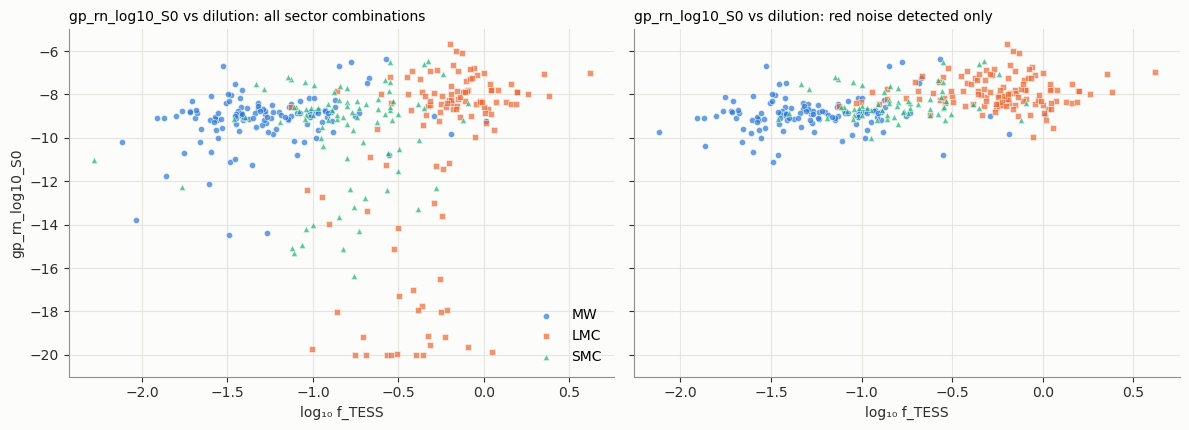

In [6]:
det_rows = rows[pd.to_numeric(rows.gp_rn_near_white_noise, errors='coerce').fillna(0) < 0.5]
ct_det = A.cluster_table(det_rows)[['name'] + RN]
dd = ct_det.merge(df[['name', 'origin', 'log_f_TESS', 'f_Gaia']], on='name', how='inner')
rb = []
for lab, data in [('all sector combos', df), ('RN-detected combos only', dd)]:
    for p in ['gp_rn_log10_S0', 'gp_rn_rms_band', 'rn_log10_N', 'gp_rn_alpha_band', 'rn_alpha']:
        for o in GAL:
            d = data[data.origin == o][[p, 'log_f_TESS']].dropna()
            if len(d) < 15:
                continue
            ts = stats.theilslopes(d[p], d.log_f_TESS)
            rb.append(dict(sample=lab, param=p, origin=o, n=len(d), predicted=PRED_SLOPE[p],
                           theil_sen=ts[0], lo=ts[2], hi=ts[3],
                           rho=stats.spearmanr(d.log_f_TESS, d[p])[0]))
rb = pd.DataFrame(rb)
display(rb.pivot_table(index=['param', 'origin'], columns='sample', values=['theil_sen', 'rho']).round(2))

fig, axs = plt.subplots(1, 2, figsize=(12, 4.4), sharey=True)
for ax, (lab, data) in zip(axs, [('all sector combinations', df), ('red noise detected only', dd)]):
    for o in GAL:
        d = data[data.origin == o]
        ax.scatter(d.log_f_TESS, d.gp_rn_log10_S0, s=20, marker=MRK[o], color=COL[o], alpha=.7,
                   edgecolor='#fcfcfb', lw=.5, label=o)
    ax.set(xlabel='log₁₀ f_TESS', ylim=(-21, -5))
    ax.set_title(f'gp_rn_log10_S0 vs dilution: {lab}', loc='left', fontsize=10)
axs[0].set_ylabel('gp_rn_log10_S0'); axs[0].legend(loc='lower right')
fig.tight_layout(); save(fig, 'fig_rn_S0_detected_only.png'); plt.show()

## 5 · Is red noise less often detected where the cluster is more diluted?

`frac_gp_rn_near_white_noise` is the fraction of a cluster's sector combinations whose GP red
noise is < 5% of the white noise at 1 day⁻¹, i.e. effectively undetected. Dilution lowers the
red noise relative to photon noise, so diluted clusters should be undetected more often.

In [7]:
flag = [c for c in df.columns if c.startswith('frac_gp_rn_near')]
if flag:
    fcol = flag[0]
    out = []
    for o in SUBSETS:
        d = df if o == 'all' else df[df.origin == o]
        r1 = A.spearman_ci(d.log_f_TESS, d[fcol], n_boot=1000, seed=0)
        r2 = A.spearman_ci(d.f_Gaia, d[fcol], n_boot=1000, seed=0)
        out.append(dict(subset=o, n=len(d), median_frac_undetected=d[fcol].median(),
                        rho_fTESS=r1[0], ci_fTESS=f'[{r1[2][0]:+.2f}, {r1[2][1]:+.2f}]',
                        rho_fGaia=r2[0], ci_fGaia=f'[{r2[2][0]:+.2f}, {r2[2][1]:+.2f}]'))
    display(pd.DataFrame(out).set_index('subset').round(3))

,n,median_frac_undetected,rho_fTESS,ci_fTESS,rho_fGaia,ci_fGaia
subset,,,,,,
MW,124,0.000,-0.112,"[-0.28, +0.07]",0.122,"[-0.07, +0.28]"
LMC,118,0.107,-0.520,"[-0.66, -0.36]",-0.327,"[-0.51, -0.16]"
SMC,106,0.000,-0.024,"[-0.25, +0.19]",-0.174,"[-0.34, +0.00]"
all,348,0.000,0.331,"[+0.24, +0.42]",0.183,"[+0.08, +0.29]"


## 6 · Does the red-noise–age relation survive controlling for f_cl?

For each RN parameter: Spearman ρ with age, raw and partial (both ranks residualised on log
f_TESS), per galaxy. If an RN–age correlation is carried by dilution, the partial ρ should move
toward 0. This is descriptive only; it is not the full nuisance model of `Correlation_Analysis/`.

rho_raw             rho_partial            
origin               LMC    MW   SMC         LMC    MW   SMC
param                                                       
gp_jitter          -0.60 -0.05 -0.03       -0.47 -0.06  0.02
gp_rn_alpha_band   -0.41  0.09 -0.18       -0.23  0.08 -0.15
gp_rn_log10_S0     -0.41  0.00 -0.11       -0.21 -0.00 -0.08
gp_rn_rms_band     -0.42  0.01 -0.10       -0.22  0.00 -0.07
gp_rn_wn_ratio     -0.52  0.05 -0.09       -0.36  0.05 -0.06
rn_alpha           -0.59 -0.07 -0.26       -0.46 -0.07 -0.23
rn_log10_N         -0.58 -0.06 -0.15       -0.47 -0.06 -0.10

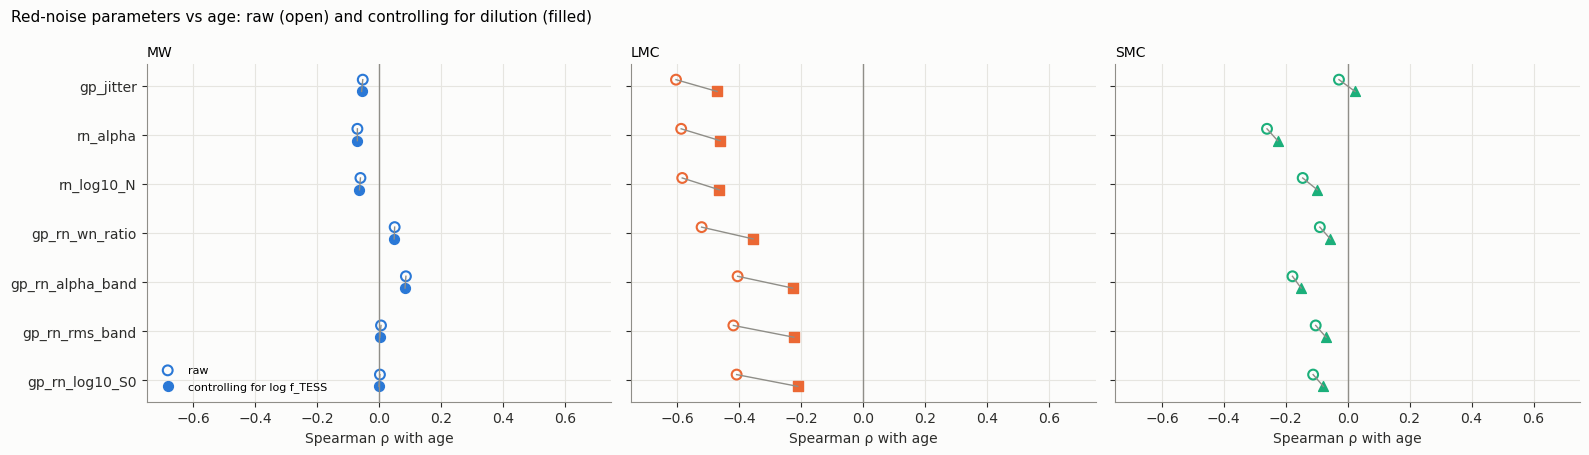

In [8]:
med = []
for p in RN:
    for o in GAL:
        d = df[df.origin == o][[p, 'age', 'log_f_TESS']].dropna()
        if len(d) < 20:
            continue
        r_raw, p_raw, (lo_r, hi_r) = A.spearman_ci(d[p], d.age, n_boot=500, seed=0)
        r_par, p_par, (lo_p, hi_p), n = A.partial_spearman_ci(d, p, 'age', ['log_f_TESS'], n_boot=300, seed=0)
        med.append(dict(param=p, origin=o, n=len(d), rho_raw=r_raw, ci_raw=f'[{lo_r:+.2f}, {hi_r:+.2f}]',
                        rho_partial=r_par, ci_partial=f'[{lo_p:+.2f}, {hi_p:+.2f}]'))
med = pd.DataFrame(med)
display(med.pivot(index='param', columns='origin', values=['rho_raw', 'rho_partial']).round(2))

fig, axs = plt.subplots(1, 3, figsize=(16, 4.6), sharey=True)
y = np.arange(len(RN))
for ax, o in zip(axs, GAL):
    m = med[med.origin == o].set_index('param').reindex(RN)
    ax.scatter(m.rho_raw, y + 0.12, marker='o', facecolor='none', edgecolor=COL[o], s=50, lw=1.5, label='raw')
    ax.scatter(m.rho_partial, y - 0.12, marker=MRK[o], color=COL[o], s=50, label='controlling for log f_TESS')
    for yi, a, b in zip(y, m.rho_raw, m.rho_partial):
        ax.plot([a, b], [yi + 0.12, yi - 0.12], color=MUTED, lw=1)
    ax.axvline(0, color=MUTED, lw=1)
    ax.set(xlabel='Spearman ρ with age', xlim=(-0.75, 0.75))
    ax.set_title(f'{o}', loc='left', fontsize=10)
axs[0].set_yticks(y); axs[0].set_yticklabels(RN); axs[0].legend(loc='lower left', fontsize=8)
fig.suptitle('Red-noise parameters vs age: raw (open) and controlling for dilution (filled)', x=0.01, ha='left', fontsize=11)
fig.tight_layout(); save(fig, 'fig_rn_age_partial_fcl.png'); plt.show()

## 7 · Summary

In [9]:
print('CONCLUSION —')
for fm in FMEAS:
    r = res[(res.fmeas == fm) & (res.subset != 'all') & (res.q < 0.05)].sort_values('rho', key=abs, ascending=False)
    print(f'  {FMEAS[fm]}: {len(r)} significant per-galaxy correlations (q < 0.05)')
    for _, x in r.head(8).iterrows():
        print(f'     {x.subset:>3s} {x.param:18s} rho = {x.rho:+.2f} [{x.lo:+.2f}, {x.hi:+.2f}]')
s0 = sl[sl.param == 'gp_rn_log10_S0'].set_index('origin')
print('  OLS slope of gp_rn_log10_S0 on log f_TESS (dilution predicts +2): ' +
      ', '.join(f'{o} {s0.loc[o, "slope"]:+.2f} [{s0.loc[o, "lo"]:+.2f}, {s0.loc[o, "hi"]:+.2f}]' for o in GAL))

CONCLUSION —
  log₁₀ f_TESS: 8 significant per-galaxy correlations (q < 0.05)
     LMC gp_jitter          rho = +0.50 [+0.34, +0.63]
     LMC gp_rn_wn_ratio     rho = +0.47 [+0.30, +0.61]
     LMC gp_rn_rms_band     rho = +0.45 [+0.29, +0.59]
     LMC gp_rn_log10_S0     rho = +0.45 [+0.29, +0.59]
     LMC rn_alpha           rho = +0.44 [+0.28, +0.58]
     LMC rn_log10_N         rho = +0.43 [+0.27, +0.57]
     LMC gp_rn_alpha_band   rho = +0.41 [+0.25, +0.56]
     SMC gp_jitter          rho = +0.27 [+0.05, +0.44]
  f_Gaia: 15 significant per-galaxy correlations (q < 0.05)
     LMC gp_jitter          rho = +0.52 [+0.38, +0.62]
     LMC rn_log10_N         rho = +0.45 [+0.31, +0.58]
     LMC rn_alpha           rho = +0.39 [+0.23, +0.55]
      MW rn_log10_N         rho = +0.39 [+0.21, +0.54]
     LMC gp_rn_wn_ratio     rho = +0.38 [+0.22, +0.54]
      MW rn_alpha           rho = +0.38 [+0.19, +0.54]
     LMC gp_rn_rms_band     rho = +0.28 [+0.11, +0.44]
      MW gp_rn_alpha_band   rho = +0.

**Interpretation:**
1. **In the LMC, every red-noise parameter correlates with the cluster share** (ρ ≈ +0.4 to
   +0.5 for both f_TESS and f_Gaia; jitter is strongest at +0.5). In the MW and SMC the
   correlations are weak (≤ 0.3) and mostly appear only with f_Gaia.
2. **It isn't the dilution scaling.** Amplitudes are supposed to scale as f² (S0) and f (rms),
   and slopes (α) are supposed not to change. Instead:
   - the LMC α parameters correlate with f_cl as strongly as the amplitudes do;
   - restricted to sector combinations where red noise is detected, the GP S0, rms and α
     slopes vs f_TESS collapse to ≈ 0 (ρ ≈ −0.05 to −0.02; §4b). The Lomb–Scargle
     parameters keep a moderate correlation (`rn_log10_N` ρ = +0.32, Theil–Sen slope +0.48;
     `rn_alpha` +0.34). The GP detection flag doesn't filter those fits, and the slope is still
     about 4× shallower than the +2 dilution predicts.

   So the red noise that *is* detected doesn't look like cluster variability diluted by a
   quiet field. What dilution does is control **detection**: the more diluted an LMC cluster,
   the more often its red noise drops below the white noise (ρ = −0.52, §5). Undetected fits
   then pull the cluster medians of every RN parameter down (amplitude toward zero, α to
   whatever the fit settles on).
3. **Age.** In the LMC, controlling for log f_TESS roughly halves the red-noise–age correlations
   (e.g. S0: −0.41 → −0.21; α_band: −0.41 → −0.23). The LSP-based parameters and the jitter keep
   more of theirs (−0.47). In the MW and SMC, red noise barely tracks age, and controlling for
   f_cl changes nothing.
4. **Pooled ("all") correlations** mix galaxies with very different f_cl. Several change sign
   relative to the per-galaxy values (e.g. `rn_log10_N` −0.39 pooled vs +0.43 LMC), so they
   shouldn't be interpreted.

**Bottom line:** in the LMC, much of what the red-noise parameters "know" about age is whether
red noise is detectable at all, which is set by how diluted the cluster is.